# Feature Engineering - определение факта сделки на Авито
**Задача:** бинарная классификация `is_deal`.

Цель - подготовить признаки на уровне объявления и сравнить их вклад в качество логистической регрессии.

## 1. Загрузка данных и базовые проверки
### 1.1. Библиотеки и вспомогательные функции

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
for path in sorted(Path("data").rglob("*.csv")):
    print(path)


def safe_divide(numerator, denominator):
    return numerator / denominator.replace(0, np.nan)

data\data_ONLY_anomailes\anomalies_bad_time\events_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_bad_time\listings_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_bad_time\messages_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_bad_time\surveys_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_high_listing_ids\events_anomalies_high_listing_ids.csv
data\data_ONLY_anomailes\anomalies_high_listing_ids\listings_anomalies_high_listing_ids.csv
data\data_ONLY_anomailes\anomalies_high_listing_ids\messages_anomalies_high_listing_ids.csv
data\data_ONLY_anomailes\anomalies_high_listing_ids\surveys_anomalies_high_listing_ids.csv
data\data_ONLY_anomailes\anomalies_low_listing_ids\events_anomalies_low_listing_ids.csv
data\data_ONLY_anomailes\anomalies_low_listing_ids\listings_anomalies_low_listing_ids.csv
data\data_ONLY_anomailes\anomalies_low_listing_ids\messages_anomalies_low_listing_ids.csv
data\data_ONLY_anomailes\anomalies_low_listing_ids\surveys_anomali

### 1.2. Чтение исходных таблиц
Пути соответствуют структуре репозитория команды. Проверяем размеры, типы, пропуски и дубликаты.

In [3]:
DATA = Path("data/data_wthout_anomailes")

listings = pd.read_csv(DATA / "listings_wthout_anomailes.csv")
events = pd.read_csv(DATA / "events_wthout_anomailes.csv")
messages = pd.read_csv(DATA / "messages_wthout_anomailes.csv")
surveys = pd.read_csv(DATA / "surveys_wthout_anomailes.csv")

verified = pd.read_csv("data/verified.csv")

tables = {
    "listings": listings,
    "events": events,
    "messages": messages,
    "surveys": surveys,
    "verified": verified
}

for name, df in tables.items():
    print(f"\n{name}: {df.shape}")
    print(df.dtypes)
    print("Дубликатов:", df.duplicated().sum())
    print("Пропуски:")
    print(df.isna().sum())


listings: (15051, 18)
listing_id              int64
seller_id               int64
seller_type               str
category                  str
title                     str
price                   int64
current_price           int64
photos_count            int64
description_length    float64
region                    str
published_at              str
closed_at                 str
close_type                str
views_total             int64
favorites_total         int64
phone_views_total       int64
chats_total             int64
messages_total          int64
dtype: object
Дубликатов: 0
Пропуски:
listing_id              0
seller_id               0
seller_type             0
category              379
title                   0
price                   0
current_price           0
photos_count            0
description_length    449
region                  0
published_at            0
closed_at               0
close_type              0
views_total             0
favorites_total         0
phone_vie

In [4]:
# Проверка ключей перед построением признаков.
assert listings["listing_id"].is_unique, "В listings есть повторяющиеся ID"
assert verified["listing_id"].is_unique, "В verified есть повторяющиеся ID"
assert verified["is_deal"].isin([0, 1]).all(), "Некорректная разметка"

## 2. Listings - признаки объявления
### 2.1. Исследование данных
Отбираем размеченные объявления, присутствующие в очищенной таблице. Идентификаторы не используются как признаки модели.

In [5]:
display(listings.head())
display(listings.describe().T)

for col in ["seller_type", "category", "region", "close_type"]:
    print(f"\n{col}:")
    print(listings[col].value_counts(dropna=False))

verified_clean = verified[
    verified["listing_id"].isin(listings["listing_id"])
]

print("Всего verified:", len(verified))
print("После очистки:", len(verified_clean))
print(verified_clean["is_deal"].value_counts())

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
0,132065,31904,private,Одежда и обувь,Пуховик женский б/у,570,470,3,130.0,Москва,2026-09-07 19:40:26,2026-09-22 11:05:13,снято продавцом,193,10,0,4,21
1,117997,24387,private,Мебель и интерьер,Комод,2080,2080,6,128.0,СПб,2026-08-22 18:11:20,2026-09-06 17:09:12,снято продавцом,140,6,1,4,25
2,129810,20372,private,Одежда и обувь,Пуховик женский б/у,1320,1320,8,202.0,Москва,2026-09-05 16:07:34,2026-09-08 15:10:57,снято продавцом,50,1,0,4,23
3,111780,13149,private,Спорт и отдых,Спальный мешок,5030,5030,3,82.0,Санкт-Петербург,2026-08-15 14:31:56,2026-09-14 14:31:56,истёк срок,245,9,2,10,44
4,118819,24952,private,Электроника,Смартфон Samsung Galaxy A52 как новый,15880,13340,3,80.0,Санкт-Петербург,2026-08-23 18:13:12,2026-08-26 12:27:38,снято продавцом,11,0,0,1,6


,count,mean,std,min,25%,50%,75%,max
listing_id,15051.0,130630.624543,17672.830473,100004.0,115428.0,130504.0,145960.5,161269.0
seller_id,15051.0,23047.592319,8705.960702,10001.0,15312.0,21986.0,30001.0,41169.0
price,15051.0,7696.746396,8373.611675,120.0,2290.0,4890.0,9945.0,105640.0
current_price,15051.0,7472.874228,8144.042498,120.0,2220.0,4760.0,9635.0,105640.0
photos_count,15051.0,4.236330,2.176351,0.0,3.0,4.0,6.0,10.0
description_length,14602.0,141.496233,126.278364,9.0,65.0,105.0,174.0,1997.0
views_total,15051.0,137.102252,148.104275,0.0,37.0,83.0,189.0,1624.0
favorites_total,15051.0,4.486878,5.053653,0.0,1.0,3.0,6.0,49.0
phone_views_total,15051.0,1.388612,1.919925,0.0,0.0,1.0,2.0,20.0
chats_total,15051.0,5.804664,6.622872,0.0,2.0,3.0,8.0,70.0



seller_type:
seller_type
private     13653
business     1398
Name: count, dtype: int64

category:
category
Электроника              3254
Одежда и обувь           3166
Детские товары           2029
Мебель и интерьер        1872
Запчасти и аксессуары    1541
Бытовая техника          1511
Спорт и отдых            1299
NaN                       379
Name: count, dtype: int64

region:
region
Москва             4110
Санкт-Петербург    2783
Краснодар          1284
Екатеринбург       1233
Новосибирск        1219
Казань             1193
Нижний Новгород    1060
Самара              967
Москва              102
Moscow               91
г. Москва            87
москва               81
краснодар            71
СПб                  66
Питер                62
санкт-петербург      59
г. Краснодар         58
самара               56
г. Казань            55
казань               55
екатеринбург         54
Санкт Петербург      51
Екб                  48
г. Новосибирск       46
нижний новгород      43
новосибирс

### 2.2. Нормализация региона
Приводим разные написания одного города к единому значению. Рабочая таблица `features` начинается с копии listings.

In [6]:
features = listings.copy()

features["region"] = (
    features["region"]
    .str.strip()
    .str.lower()
    .str.replace(r"^г\.\s*", "", regex=True)
)

region_map = {
    "moscow": "москва",
    "масква" : "москва",
    "мск" : "москва",
    "спб": "санкт-петербург",
    "санкт-питербург" : "санкт-петербург",
    "msk" : "москва",
    "питер": "санкт-петербург",
    "санкт петербург": "санкт-петербург",
    "екб": "екатеринбург",
    "новосиб" : "новосибирск",
    "н. новгород": "нижний новгород"
}

features["region"] = features["region"].replace(region_map)

print(features["region"].value_counts())

region
москва             4471
санкт-петербург    3021
краснодар          1413
екатеринбург       1335
новосибирск        1306
казань             1303
нижний новгород    1139
самара             1063
Name: count, dtype: int64


### 2.3. Восстановление категорий и индикатор пропусков
Проверяем однозначность соответствия заголовка категории. Пропуски длины описания оставляем для импутации в модели и отмечаем бинарным флагом.

In [7]:
print("Всего объявлений:", len(features))
print("Уникальных заголовков:", features["title"].nunique())

display(features["title"].value_counts().head(20))

display(
    features.loc[
        features["category"].isna(),
        ["title", "price", "category"]
    ].head(30)
)

title_categories = (
    features.dropna(subset=["category"])
    .groupby("title")["category"]
    .nunique()
)

print(title_categories.value_counts())

features["description_missing"] = (
    features["description_length"].isna().astype(int)
)

Всего объявлений: 15051
Уникальных заголовков: 720


title
Рюкзак городской               93
Кроссовки Nike                 86
Джинсы Levi's                  80
Худи оверсайз                  79
Видеокарта GTX 1660            75
Колонка JBL                    74
Смартфон Samsung Galaxy A52    73
Свитер вязаный                 71
Платье вечернее                71
Сапоги зимние                  70
Наушники беспроводные          68
Костюм мужской                 68
Фотоаппарат Canon              67
Электронная книга              66
Монитор 24 дюйма               63
Пальто шерстяное               62
Игровая приставка              62
Ботинки кожаные                62
iPhone 12 128 ГБ               59
Пуховик женский                59
Name: count, dtype: int64

,title,price,category
6,Наушники беспроводные с документами,7510,NaN
108,Электроплита,11130,NaN
154,Стеллаж,2890,NaN
212,Роутер Wi-Fi новый,12830,NaN
213,iPhone 12 128 ГБ с документами,4680,NaN
282,Кофемашина DeLonghi отличное состояние,10570,NaN
342,Умные часы б/у,15610,NaN
353,Автокресло новый,11960,NaN
402,Смартфон Samsung Galaxy A52 как новый,33270,NaN
425,Видеокарта GTX 1660,7890,NaN


category
1    720
Name: count, dtype: int64


In [8]:
# Восстановление категории по известным заголовкам.

title_to_category = (
    features.dropna(subset=["category"])
    .groupby("title")["category"]
    .first()
    .to_dict()
)

features["category"] = features["category"].fillna(
    features["title"].map(title_to_category)
)

print("Осталось пропусков:", features["category"].isna().sum())

Осталось пропусков: 0


### 2.4. Заголовки и относительная цена
Выделяем состояние товара и другие суффиксы, затем убираем их для получения базового названия товара. Медианная цена группы позволяет сравнивать разные товары на общей шкале.

In [9]:
title = features["title"].str.lower().str.strip()

features["is_used"] = title.str.endswith(" б/у").astype(int)
features["is_new"] = (
    title.str.endswith(" новый")
    & ~title.str.endswith(" как новый")
).astype(int)

features["is_like_new"] = title.str.endswith(" как новый").astype(int)
features["has_documents"] = title.str.endswith(" с документами").astype(int)
features["is_negotiable"] = title.str.endswith(" торг").astype(int)
features["is_urgent"] = title.str.endswith(" срочно").astype(int)
features["is_excellent"] = title.str.endswith(" отличное состояние").astype(int)
features["has_package"] = title.str.contains(
    r"\b(?:коробка|коробкой|упаковка|упаковкой)\b",
    case=False,
    na=False
).astype(int)

suffix_pattern = (
    r"\s+(?:в хорошем состоянии|отличное состояние|"
    r"с документами|как новый|б/у|новый|торг|срочно)$"
)

features["base_title"] = title.str.replace(
    suffix_pattern, "", regex=True
)

features["is_good_condition"] = (
    title.str.endswith(" в хорошем состоянии").astype(int)
)

print("Товарных групп:", features["base_title"].nunique())
print(features["base_title"].value_counts().describe())

print("До:", features["title"].nunique())
print("После:", features["base_title"].nunique())

display(features["base_title"].value_counts().head(20))

# относительная цена

features["product_median_price"] = (
    features.groupby("base_title")["price"].transform("median")
)

features["relative_price"] = (
    features["price"] / features["product_median_price"]
)

features["relative_current_price"] = (
    features["current_price"] / features["product_median_price"]
)

features["log_relative_price"] = np.log(
    features["relative_price"]
)

display(
    features[
        [
            "title",
            "base_title",
            "category",
            "price",
            "product_median_price",
            "relative_price"
        ]
    ].head(15)
)

print(features["relative_price"].describe())

print(
    features["base_title"].value_counts().describe()
)

Товарных групп: 80
count     80.00000
mean     188.13750
std       51.71214
min      108.00000
25%      146.75000
50%      172.50000
75%      231.25000
max      307.00000
Name: count, dtype: float64
До: 720
После: 80


base_title
худи оверсайз             307
кроссовки nike            295
рюкзак городской          294
платье вечернее           288
костюм мужской            278
сапоги зимние             270
джинсы levi's             270
видеокарта gtx 1660       267
пальто шерстяное          260
пуховик женский           258
iphone 12 128 гб          255
наушники беспроводные     252
свитер вязаный            252
колонка jbl               251
ботинки кожаные           250
планшет huawei matepad    249
электронная книга         246
фотоаппарат canon         242
игровая приставка         241
ноутбук lenovo ideapad    235
Name: count, dtype: int64

,title,base_title,category,price,product_median_price,relative_price
0,Пуховик женский б/у,пуховик женский,Одежда и обувь,570,1530.0,0.372549
1,Комод,комод,Мебель и интерьер,2080,6510.0,0.319508
2,Пуховик женский б/у,пуховик женский,Одежда и обувь,1320,1530.0,0.862745
3,Спальный мешок,спальный мешок,Спорт и отдых,5030,5690.0,0.884007
4,Смартфон Samsung Galaxy A52 как новый,смартфон samsung galaxy a52,Электроника,15880,14630.0,1.085441
5,Самокат взрослый как новый,самокат взрослый,Спорт и отдых,5700,4885.0,1.166837
6,Наушники беспроводные с документами,наушники беспроводные,Электроника,7510,14720.0,0.510190
7,Тормозные колодки б/у,тормозные колодки,Запчасти и аксессуары,3500,4015.0,0.871731
8,Багажник на крышу как новый,багажник на крышу,Запчасти и аксессуары,4590,4410.0,1.040816
9,Палатка 4-местная,палатка 4-местная,Спорт и отдых,6280,5880.0,1.068027


count    15051.000000
mean         1.199686
std          0.794045
min          0.068966
25%          0.666667
50%          1.000000
75%          1.495956
max         10.065359
Name: relative_price, dtype: float64
count     80.00000
mean     188.13750
std       51.71214
min      108.00000
25%      146.75000
50%      172.50000
75%      231.25000
max      307.00000
Name: count, dtype: float64


### 2.5. Исследование ценовых признаков
Сопоставляем относительную цену с проверенной разметкой; группы цен используются только для анализа, не как признаки модели.

в хорошем состоянии    80
отличное состояние     80
с документами          80
как новый              80
срочно                 80
новый                  80
торг                   80
б/у                    80
Name: count, dtype: int64

(294, 34)


is_deal                                  0            1
price                  mean    8126.277778  8074.912281
                       median  4910.000000  5590.000000
                       std     9368.096581  8715.970312
relative_price         mean       1.390955     1.134301
                       median     1.154834     0.939540
                       std        1.031071     0.740892
relative_current_price mean       1.359186     1.099220
                       median     1.111190     0.910343
                       std        1.025536     0.743792
log_relative_price     mean       0.122212    -0.060085
                       median     0.143841    -0.062411
                       std        0.638216     0.617041

,total,deals,deal_rate
price_group,,,
Очень дешёвый,34,16,0.470588
Дешёвый,65,31,0.476923
Рыночная цена,67,25,0.373134
Дорогой,39,17,0.435897
Очень дорогой,89,25,0.280899


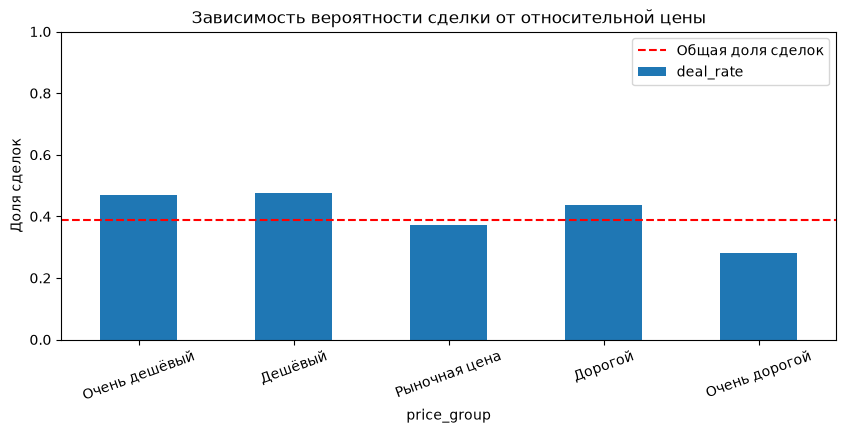

In [10]:
unique_titles = sorted(
    title.dropna().unique(),
    key=len,
    reverse=True
)

suffixes = []

for full_title in unique_titles:
    for short_title in unique_titles:
        if full_title.startswith(short_title + " "):
            suffix = full_title[len(short_title):].strip()
            suffixes.append(suffix)
            break

display(pd.Series(suffixes).value_counts())

research = features.merge(
    verified,
    on="listing_id",
    how="inner",
    validate="one_to_one"
)

print(research.shape)

display(
    research.groupby("is_deal")[
        [
            "price",
            "relative_price",
            "relative_current_price",
            "log_relative_price"
        ]
    ].agg(["mean", "median", "std"]).T
)

research["price_group"] = pd.cut(
    research["relative_price"],
    bins=[0, 0.5, 0.8, 1.2, 1.5, np.inf],
    labels=[
        "Очень дешёвый",
        "Дешёвый",
        "Рыночная цена",
        "Дорогой",
        "Очень дорогой"
    ]
)

price_stats = (
    research.groupby("price_group", observed=True)
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

display(price_stats)

price_stats["deal_rate"].plot(
    kind="bar",
    figsize=(10, 4),
    rot=20,
    title="Зависимость вероятности сделки от относительной цены"
)

plt.axhline(
    research["is_deal"].mean(),
    color="red",
    linestyle="--",
    label="Общая доля сделок"
)

plt.ylabel("Доля сделок")
plt.ylim(0, 1)
plt.legend()
plt.show()

### 2.6. Скидка, время жизни и способ закрытия
Считаем изменение цены и длительность размещения. Проверяем, связаны ли срок жизни и способ закрытия с фактом сделки; закрытие само по себе не гарантирует продажу.

In [11]:
# Относительная величина снижения цены
features["discount_pct"] = (
    (features["price"] - features["current_price"])
    / features["price"]
)

# Снижалась ли цена к моменту закрытия
features["has_discount"] = (
    features["current_price"] < features["price"]
).astype(int)

# Цена существенно выше медианы
features["is_overpriced"] = (
    features["relative_price"] > 1.5
).astype(int)

# Логарифм абсолютной цены
features["log_price"] = np.log1p(features["price"])

features["published_at"] = pd.to_datetime(
    features["published_at"]
)

features["closed_at"] = pd.to_datetime(
    features["closed_at"]
)

features["lifetime_hours"] = (
    features["closed_at"] - features["published_at"]
).dt.total_seconds() / 3600

features["lifetime_days"] = features["lifetime_hours"] / 24

display(features["lifetime_days"].describe())

features["is_closed_first_day"] = (
    features["lifetime_days"] <= 1
).astype(int)

features["is_closed_first_week"] = (
    features["lifetime_days"] <= 7
).astype(int)

features["log_lifetime"] = np.log1p(
    features["lifetime_days"]
)

research = features.merge(
    verified, on="listing_id", how="inner"
)

display(
    research.groupby("is_deal")["lifetime_days"]
    .agg(["mean", "median", "std", "min", "max"])
)

research["lifetime_group"] = pd.cut(
    research["lifetime_days"],
    bins=[0, 1, 3, 7, 14, 29, np.inf],
    labels=[
        "До 1 дня",
        "1–3 дня",
        "3–7 дней",
        "7–14 дней",
        "14–29 дней",
        "Более 29 дней"
    ],
    include_lowest=True
)

lifetime_stats = (
    research.groupby("lifetime_group", observed=True)
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

display(lifetime_stats)

display(
    research.groupby("close_type")
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

count    15051.000000
mean        14.845349
std         11.829440
min          0.061238
25%          4.137355
50%          9.444769
75%         30.000000
max         30.000000
Name: lifetime_days, dtype: float64

,mean,median,std,min,max
is_deal,,,,,
0,16.524821,11.929664,12.169630,0.590313,30.0
1,12.518215,8.499242,10.580727,0.814468,30.0


,total,deals,deal_rate
lifetime_group,,,
До 1 дня,5,1,0.200000
1–3 дня,38,12,0.315789
3–7 дней,69,38,0.550725
7–14 дней,64,30,0.468750
14–29 дней,14,6,0.428571
Более 29 дней,104,27,0.259615


,total,deals,deal_rate
close_type,,,
заблокировано,2,0,0.000000
истёк срок,104,27,0.259615
снято продавцом,188,87,0.462766


In [12]:
# Проверка связи длительности объявления со способом его закрытия.

display(pd.crosstab(
    research["lifetime_group"],
    research["close_type"]
))

close_type,заблокировано,истёк срок,снято продавцом
lifetime_group,,,
До 1 дня,0,0,5
1–3 дня,2,0,36
3–7 дней,0,0,69
7–14 дней,0,0,64
14–29 дней,0,0,14
Более 29 дней,0,104,0


In [13]:
# Анализ только объявлений, снятых продавцом.

display(
    research[
        research["close_type"] == "снято продавцом"
    ]
    .groupby("lifetime_group", observed=True)["is_deal"]
    .agg(["count", "sum", "mean"])
)

,count,sum,mean
lifetime_group,,,
До 1 дня,5,1,0.200000
1–3 дня,36,12,0.333333
3–7 дней,69,38,0.550725
7–14 дней,64,30,0.468750
14–29 дней,14,6,0.428571


### 2.7. Поведенческие признаки
Нормируем количество действий по просмотрам, чатам и времени жизни. `safe_divide` оставляет NaN, если знаменатель равен нулю; при расчёте дневной активности минимальный срок - один день.

In [14]:
# Конверсии просмотров в контактные действия и глубина переписки.

features["messages_per_chat"] = safe_divide(
    features["messages_total"],
    features["chats_total"]
)

features["chats_per_view"] = safe_divide(
    features["chats_total"],
    features["views_total"]
)

features["phones_per_view"] = safe_divide(
    features["phone_views_total"],
    features["views_total"]
)

features["favorites_per_view"] = safe_divide(
    features["favorites_total"],
    features["views_total"]
)

features["contacts_total"] = (
    features["chats_total"]
    + features["phone_views_total"]
)

features["contacts_per_view"] = safe_divide(
    features["contacts_total"],
    features["views_total"]
)

In [15]:
# Интенсивность активности за день.

days = features["lifetime_days"].clip(lower=1)

features["views_per_day"] = (
    features["views_total"] / days
)

features["chats_per_day"] = (
    features["chats_total"] / days
)

features["messages_per_day"] = (
    features["messages_total"] / days
)

features["contacts_per_day"] = (
    features["contacts_total"] / days
)

### 2.8. Относительные характеристики внутри товарной группы
Сравниваем активность, длину описания и время жизни с медианами похожих товаров. Не все экспериментальные признаки попадут в итоговый набор.

In [16]:
# относительная популярность товара по просмотрам

features["views_per_day_median"] = (
    features.groupby("base_title")["views_per_day"]
    .transform("median")
)

features["relative_views_per_day"] = safe_divide(
    features["views_per_day"],
    features["views_per_day_median"]
)

# относительная популярность товара по сообщениям

features["median_messages_per_chat"] = (
    features.groupby("base_title")["messages_per_chat"]
    .transform("median")
)

features["relative_messages_per_chat"] = safe_divide(
    features["messages_per_chat"],
    features["median_messages_per_chat"]
)

# относительная популярность товара по длине описания

features["median_description_length"] = (
    features.groupby("base_title")["description_length"]
    .transform("median")
)

features["relative_description_length"] = safe_divide(
    features["description_length"],
    features["median_description_length"]
)

# относительная популярность товара lifetime товара

features["median_lifetime_days"] = (
    features.groupby("base_title")["lifetime_days"]
    .transform("median")
)

features["relative_lifetime_days"] = safe_divide(
    features["lifetime_days"],
    features["median_lifetime_days"]
)

### 2.9. Отсутствие просмотров и контактов
Отдельные бинарные признаки позволяют различать отсутствие событий и пропуски в относительных величинах.

In [17]:
features["no_contacts"] = (
    features["contacts_total"] == 0
).astype(int)

features["no_chats"] = (
    features["chats_total"] == 0
).astype(int)

features["no_phone_views"] = (
    features["phone_views_total"] == 0
).astype(int)

features["no_views"] = (
    features["views_total"] == 0
).astype(int)

## 3. Surveys - ответы продавцов
### 3.1. Проверка ответов и исследование достоверности
Опрос доступен частным продавцам, снявшим объявление. Ответ - сигнал, но не целевая переменная: по сохранённым результатам 41 из 51 ответа «Продал на Авито» подтверждён разметкой. Намеренный обман из этих данных установить нельзя.

In [18]:
display(surveys.head(10))

print("Размер:", surveys.shape)

print("\nПропуски:")
print(surveys.isna().sum())

print("\nВарианты ответов:")
print(surveys["answer"].value_counts(dropna=False))

print("\nДубликаты строк:")
print(surveys.duplicated().sum())

print("\nПовторяющиеся listing_id:")
print(surveys["listing_id"].duplicated().sum())

survey_conflicts = (
    surveys.groupby("listing_id")["answer"]
    .nunique()
)

display(survey_conflicts.value_counts())

# Разделение ответов по столбцам
answers_count = surveys["answer"].value_counts()

for answer_type in answers_count.index.tolist():
    surveys[f"answer_type_{answer_type}"] = (
        surveys["answer"] == answer_type
    ).astype(int)

# Мог ли продавец получить опрос
features["survey_eligible"] = (
    (features["seller_type"] == "private")
    & (features["close_type"] == "снято продавцом")
).astype(int)

# Есть ли непустой ответ на опрос
features["survey_answered"] = (
    features["listing_id"].isin(
        surveys.loc[surveys["answer"].notna(), "listing_id"]
    )
).astype(int)

# Сопоставление ответов с проверенной разметкой.
survey_research = (
    surveys[["listing_id", "answer"]]
    .drop_duplicates()
    .merge(verified_clean, on="listing_id", how="inner")
)

display(
    survey_research.groupby("answer")
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

,listing_id,answered_at,platform,answer
0,100227,2026-08-02 10:38:45,ios,Передумал продавать
1,100431,2026-08-02 19:04:57,android,Продал в другом месте
2,100724,2026-08-02 19:49:59,web,Продал в другом месте
3,100551,2026-08-02 19:58:47,android,Передумал продавать
4,100476,2026-08-02 20:23:51,android,Продал в другом месте
5,100729,2026-08-03 08:20:57,android,Продал в другом месте
6,101270,2026-08-03 09:08:28,ios,Продал в другом месте
7,100402,2026-08-03 10:37:32,android,Продал в другом месте
8,100212,2026-08-03 11:56:04,ios,Продал на Авито
9,101248,2026-08-03 15:29:23,web,Продал на Авито


Размер: (5846, 4)

Пропуски:
listing_id     0
answered_at    0
platform       0
answer         0
dtype: int64

Варианты ответов:
answer
Продал на Авито          2439
Продал в другом месте    1641
Передумал продавать      1105
Другая причина            661
Name: count, dtype: int64

Дубликаты строк:
0

Повторяющиеся listing_id:
0


answer
1    5846
Name: count, dtype: int64

,total,deals,deal_rate
answer,,,
Другая причина,16,6,0.375000
Передумал продавать,17,1,0.058824
Продал в другом месте,28,4,0.142857
Продал на Авито,51,41,0.803922


### 3.2. Объединение с объявлениями
Используем left join: объявления без опроса сохраняются, их индикаторы ответов равны нулю. `survey_eligible` отличает потенциально доступный опрос от недоступного.

In [19]:
survey_features = [
    col for col in surveys.columns
    if col.startswith("answer_type_")
]

features = features.drop(
    columns=survey_features,
    errors="ignore"
).merge(
    surveys[["listing_id"] + survey_features],
    on="listing_id",
    how="left",
    validate="one_to_one"
)

features[survey_features] = (
    features[survey_features].fillna(0).astype(int)
)

print(features.shape)
print(features["listing_id"].is_unique)

display(
    features[
        survey_features
        + ["survey_eligible", "survey_answered"]
    ].sum()
)

(15051, 70)
True


answer_type_Продал на Авито          2439
answer_type_Продал в другом месте    1641
answer_type_Передумал продавать      1105
answer_type_Другая причина            661
survey_eligible                      9510
survey_answered                      5846
dtype: int64

## 4. Events - события покупателей
### 4.1. Исследование и проверка времени
Пропуски в user_id для изменения цены и в new_price для остальных действий закономерны. События вне интервала жизни объявления не используются в агрегациях.

In [20]:
display(events.head(15))

print("Размер:", events.shape)

print("\nТипы данных:")
print(events.dtypes)

print("\nПропуски:")
print(events.isna().sum())

print("\nДубликаты:")
print(events.duplicated().sum())

print("\nТипы событий:")
print(events["event_type"].value_counts(dropna=False))

print("\nУникальных покупателей:")
print(events["user_id"].nunique())

print("\nУникальных объявлений:")
print(events["listing_id"].nunique())

display(
    events.groupby("event_type")
    .agg(
        total=("listing_id", "count"),
        unique_listings=("listing_id", "nunique"),
        unique_users=("user_id", "nunique"),
        missing_users=("user_id", lambda x: x.isna().sum()),
        missing_prices=("new_price", lambda x: x.isna().sum())
    )
)

events["event_time"] = pd.to_datetime(
    events["event_time"],
    errors="coerce"
)

print("Некорректных дат:", events["event_time"].isna().sum())

event_check = events.merge(
    features[["listing_id", "published_at", "closed_at"]],
    on="listing_id",
    how="left",
    validate="many_to_one"
)

print(
    "Событий до публикации:",
    (event_check["event_time"] < event_check["published_at"]).sum()
)

print(
    "Событий после закрытия:",
    (event_check["event_time"] > event_check["closed_at"]).sum()
)

print(
    "Событий без соответствующего объявления:",
    event_check["published_at"].isna().sum()
)

,listing_id,event_time,event_type,user_id,new_price
0,100107,2026-08-01 12:00:59,favorite,9000001.0,NaN
1,100117,2026-08-01 12:17:15,chat_start,9000006.0,NaN
2,100031,2026-08-01 12:55:39,phone_view,9000007.0,NaN
3,100021,2026-08-01 12:58:05,favorite,9000014.0,NaN
4,100031,2026-08-01 13:05:30,favorite,9000019.0,NaN
5,100004,2026-08-01 13:28:18,chat_start,9000024.0,NaN
6,100031,2026-08-01 13:29:51,chat_start,9000029.0,NaN
7,100078,2026-08-01 14:14:04,chat_start,9000033.0,NaN
8,100078,2026-08-01 14:22:41,favorite,9000036.0,NaN
9,100220,2026-08-01 14:42:26,chat_start,9000041.0,NaN


Размер: (178737, 5)

Типы данных:
listing_id      int64
event_time        str
event_type        str
user_id       float64
new_price     float64
dtype: object

Пропуски:
listing_id         0
event_time         0
event_type         0
user_id         2939
new_price     175798
dtype: int64

Дубликаты:
0

Типы событий:
event_type
chat_start      87366
favorite        67532
phone_view      20900
price_change     2939
Name: count, dtype: int64

Уникальных покупателей:
65989

Уникальных объявлений:
14575


,total,unique_listings,unique_users,missing_users,missing_prices
event_type,,,,,
chat_start,87366,13611,42673,0,87366
favorite,67532,12444,35556,0,67532
phone_view,20900,8600,14734,0,20900
price_change,2939,2939,0,2939,0


Некорректных дат: 0
Событий до публикации: 27
Событий после закрытия: 0
Событий без соответствующего объявления: 0


In [21]:
events_clean = event_check.loc[
    (event_check["event_time"] >= event_check["published_at"])
    & (event_check["event_time"] <= event_check["closed_at"])
].copy()

print("До очистки:", len(events))
print("После очистки:", len(events_clean))

До очистки: 178737
После очистки: 178710


### 4.2. Уникальные покупатели и контактные действия
Контакты - начало чата и открытие номера телефона, а не подтверждённые звонки. Считаем количество разных пользователей и действий.

In [22]:
contact_events = events_clean[
    events_clean["event_type"].isin(
        ["chat_start", "phone_view"]
    )
].copy()

buyer_features = (
    events_clean.groupby("listing_id")
    .agg(
        unique_buyers=("user_id", "nunique"),
        buyer_actions=("user_id", "count")
    )
)

contact_features = (
    contact_events.groupby("listing_id")
    .agg(
        unique_contact_buyers=("user_id", "nunique"),
        contact_actions=("user_id", "count")
    )
)

display(buyer_features.head())
display(contact_features.head())

,unique_buyers,buyer_actions
listing_id,,
100004,22,22
100009,21,21
100012,2,2
100013,3,3
100019,12,12


,unique_contact_buyers,contact_actions
listing_id,,
100004,14,14
100009,13,13
100012,1,1
100013,2,2
100019,7,7


### 4.3. Агрегация событий и временная структура
Считаем среднее число действий на пользователя, время до первого и после последнего контакта, длительность контактной активности. Счётчики для отсутствующих событий заполняются нулями, неопределённые интервалы остаются NaN.

In [23]:
event_features = buyer_features.join(
    contact_features,
    how="left"
).fillna(0)

event_features["actions_per_buyer"] = safe_divide(
    event_features["buyer_actions"],
    event_features["unique_buyers"]
)

event_features["contacts_per_buyer"] = safe_divide(
    event_features["contact_actions"],
    event_features["unique_contact_buyers"]
)

contact_time = (
    contact_events.groupby("listing_id")
    .agg(
        first_contact=("event_time", "min"),
        last_contact=("event_time", "max"),
        published_at=("published_at", "first"),
        closed_at=("closed_at", "first")
    )
)

contact_time["hours_before_first_contact"] = (
    contact_time["first_contact"]
    - contact_time["published_at"]
).dt.total_seconds() / 3600

contact_time["hours_after_last_contact"] = (
    contact_time["closed_at"]
    - contact_time["last_contact"]
).dt.total_seconds() / 3600

contact_time["contact_activity_span"] = (
    contact_time["last_contact"]
    - contact_time["first_contact"]
).dt.total_seconds() / 3600

event_features = event_features.join(
    contact_time[
        [
            "hours_before_first_contact",
            "hours_after_last_contact",
            "contact_activity_span"
        ]
    ],
    how="left"
)

event_columns = event_features.columns.tolist()

features = features.drop(
    columns=event_columns,
    errors="ignore"
).merge(
    event_features.reset_index(),
    on="listing_id",
    how="left",
    validate="one_to_one"
)

count_columns = [
    "unique_buyers",
    "buyer_actions",
    "unique_contact_buyers",
    "contact_actions"
]

features[count_columns] = (
    features[count_columns].fillna(0).astype(int)
)

print(features.shape)
print(features["listing_id"].is_unique)

(15051, 79)
True


### 4.4. Экспериментальные бинарные признаки
Тип последнего контакта и наличие обоих типов контактов. Оба признака остаются в полной таблице, но пока не включены в выбранный набор.

In [24]:
# последнее действие - открытие телефона
events_dd_by_listing_id = contact_events.sort_values("event_time", ascending=False).drop_duplicates(subset="listing_id", keep="first")

phone_listing_ids = events_dd_by_listing_id.loc[
    events_dd_by_listing_id["event_type"] == "phone_view",
    "listing_id"
]

features["phone_view_is_last_event"] = (
    features["listing_id"].isin(phone_listing_ids)
).astype(int)

display(features["phone_view_is_last_event"].value_counts())

phone_view_is_last_event
0    12023
1     3028
Name: count, dtype: int64

In [25]:
contact_types = (
    contact_events.groupby("listing_id")["event_type"]
    .nunique()
)
both_contacts = contact_types[contact_types == 2]
features["has_both_contact_types"] = (
    features["listing_id"].isin(both_contacts.index)
).astype(int)

## 5. Messages - структура переписок
### 5.1. Первичный анализ
Текст сообщений не используется в этом ноутбуке; исследуются количество, авторы и время отправки. Семантические признаки разрабатываются отдельно.

In [26]:
display(messages.head(10))

print("Размер:", messages.shape)

print("\nТипы данных:")
print(messages.dtypes)

print("\nПропуски:")
print(messages.isna().sum())

print("\nДубликаты:")
print(messages.duplicated().sum())

print("\nАвторы сообщений:")
print(messages["author"].value_counts(dropna=False))

print("\nКоличество диалогов:")
print(messages["chat_id"].nunique())

print("\nКоличество объявлений:")
print(messages["listing_id"].nunique())

,chat_id,listing_id,sent_at,author,text
0,690148,139287,2026-09-20 21:35:34,buyer,"Здравствуйте, можно посмотреть?"
1,690148,139287,2026-09-21 11:27:31,seller,"Да, можно посмотреть"
2,690148,139287,2026-09-21 13:30:34,buyer,сколько лет использовали?
3,690148,139287,2026-09-21 15:27:13,seller,Около года
4,690148,139287,2026-09-21 18:51:57,buyer,Есть дефекты?
5,690148,139287,2026-09-21 22:52:33,seller,Дефектов нет
6,690148,139287,2026-09-22 07:19:26,buyer,"Дорого, спасибо"
7,663333,139287,2026-09-15 21:57:04,buyer,Актуально?
8,663333,139287,2026-09-16 07:03:31,seller,"здравствуйте, да"
9,663333,139287,2026-09-16 11:14:34,buyer,А почему продаёте


Размер: (346850, 5)

Типы данных:
chat_id       int64
listing_id    int64
sent_at         str
author          str
text            str
dtype: object

Пропуски:
chat_id          0
listing_id       0
sent_at          0
author           0
text          1391
dtype: int64

Дубликаты:
0

Авторы сообщений:
author
buyer     199808
seller    147042
Name: count, dtype: int64

Количество диалогов:
87366

Количество объявлений:
13611


In [27]:
# Распределение количества сообщений на один диалог.

chat_sizes = (
    messages.groupby(["listing_id", "chat_id"])
    .size()
)

display(chat_sizes.describe())

display(chat_sizes.value_counts().sort_index().head(30))

count    87366.000000
mean         3.970080
std          3.211704
min          1.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         23.000000
dtype: float64

1     17536
2     18273
3     10659
4     14702
5      8315
6      6674
7      3211
8       515
9       708
10      970
11     1218
12     1006
13     1207
14      768
15      697
16      407
17      303
18      114
19       54
20       25
21        3
23        1
Name: count, dtype: int64

### 5.2. Очистка времени
Исключаем сообщения вне времени жизни объявления. Пустой текст не является причиной удаления для количественного анализа.

In [28]:
messages["sent_at"] = pd.to_datetime(
    messages["sent_at"], errors="coerce"
)

message_check = messages.merge(
    features[["listing_id", "published_at", "closed_at"]],
    on="listing_id",
    how="left",
    validate="many_to_one"
)

messages_clean = message_check[
    (message_check["sent_at"] >= message_check["published_at"])
    & (message_check["sent_at"] <= message_check["closed_at"])
].copy()

print("До очистки:", len(messages))
print("После очистки:", len(messages_clean))
print("Исключено:", len(messages) - len(messages_clean))

До очистки: 346850
После очистки: 346411
Исключено: 439


### 5.3. Статистика на уровне чата
Группировка по listing_id и chat_id. Длинный диалог определён как восемь и более сообщений - исследовательская гипотеза на основе распределения длин.

In [29]:
chat_stats = (
    messages_clean.groupby(["listing_id", "chat_id"])
    .agg(
        messages_count=("author", "size"),
        seller_messages=("author", lambda x: (x == "seller").sum()),
        buyer_messages=("author", lambda x: (x == "buyer").sum()),
        first_message=("sent_at", "min"),
        last_message=("sent_at", "max")
    )
)

display(chat_stats.head(10))

messages_count  seller_messages  buyer_messages  \
listing_id chat_id                                                    
100004     500010                1                0               1   
           500621                6                3               3   
           501357                2                1               1   
           507918                1                0               1   
           509801                1                0               1   
           521926                2                1               1   
           526057                6                3               3   
           532981                6                2               4   
           533233                2                1               1   
           534205                6                3               3   

                         first_message        last_message  
listing_id chat_id                                          
100004     500010  2026-08-01 13:28:45 2026-08-01 13:28:45  
           500621  2026-08-02 23:42:44 2026-08-04 08:24:23  
           501357  2026-08-03 21:29:49 2026-08-04 07:49:31  
           507918  2026-08-08 13:53:11 2026-08-08 13:53:11  
           509801  2026-08-09 12:48:38 2026-08-09 12:48:38  
           521926  2026-08-14 11:47:58 2026-08-14 19:30:53  
           526057  2026-08-15 17:52:16 2026-08-16 17:44:28  
           532981  2026-08-17 19:47:10 2026-08-19 16:04:16  
           533233  2026-08-17 20:37:45 2026-08-18 12:32:41  
           534205  2026-08-18 10:51:29 2026-08-19 14:55:57

In [30]:
chat_stats["is_unanswered"] = (
    chat_stats["seller_messages"] == 0
).astype(int)

chat_stats["is_long_chat"] = (
    chat_stats["messages_count"] >= 8
).astype(int)

chat_stats["chat_duration_hours"] = (
    chat_stats["last_message"]
    - chat_stats["first_message"]
).dt.total_seconds() / 3600

message_features = (
    chat_stats.groupby("listing_id")
    .agg(
        max_messages_in_chat=("messages_count", "max"),
        median_chat_length=("messages_count", "median"),
        std_chat_length=("messages_count", "std"),
        total_chat_messages=("messages_count", "sum"),
        seller_messages_total=("seller_messages", "sum"),
        unanswered_chats_share=("is_unanswered", "mean"),
        long_chats_count=("is_long_chat", "sum"),
        long_chats_share=("is_long_chat", "mean"),
        max_chat_duration=("chat_duration_hours", "max")
    )
)

message_features["dominant_chat_share"] = safe_divide(
    message_features["max_messages_in_chat"],
    message_features["total_chat_messages"]
)

message_features["seller_message_share"] = safe_divide(
    message_features["seller_messages_total"],
    message_features["total_chat_messages"]
)

### 5.4. Присоединение признаков диалогов
Агрегаты на уровне объявления присоединяются по listing_id; нулями заполняются только счётчики.

In [31]:
message_columns = message_features.columns.tolist()

features = features.drop(
    columns=message_columns,
    errors="ignore"
).merge(
    message_features.reset_index(),
    on="listing_id",
    how="left",
    validate="one_to_one"
)

message_count_columns = [
    "max_messages_in_chat",
    "total_chat_messages",
    "seller_messages_total",
    "long_chats_count"
]

features[message_count_columns] = (
    features[message_count_columns].fillna(0).astype(int)
)


print(features.shape)
print(features["listing_id"].is_unique)

(15051, 92)
True


### 5.5. Скорость ответа продавца
Сортируем сообщения внутри диалога; `shift(1)` даёт предыдущего автора и время. Время ответа считается от непосредственно предшествующего сообщения покупателя, а не от первого сообщения серии.

In [32]:
messages_sorted = messages_clean.sort_values(
    ["listing_id", "chat_id", "sent_at"]
).copy()

message_groups = messages_sorted.groupby(
    ["listing_id", "chat_id"]
)

messages_sorted["prev_author"] = (
    message_groups["author"].shift(1)
)

messages_sorted["prev_time"] = (
    message_groups["sent_at"].shift(1)
)

seller_replies = messages_sorted[
    (messages_sorted["author"] == "seller")
    & (messages_sorted["prev_author"] == "buyer")
].copy()

seller_replies["reply_hours"] = (
    seller_replies["sent_at"]
    - seller_replies["prev_time"]
).dt.total_seconds() / 3600

features["median_seller_reply_hours"] = (
    features["listing_id"].map(
        seller_replies.groupby("listing_id")["reply_hours"]
        .median()
    )
)

### 5.6. Активность переписки перед закрытием
Время после последнего сообщения и число сообщений за последние 24 часа. Для объявлений без сообщений время неизвестно, количество равно нулю.

In [33]:
messages_clean["hours_until_close"] = (
    messages_clean["closed_at"]
    - messages_clean["sent_at"]
).dt.total_seconds() / 3600

features["hours_after_last_message"] = (
    features["listing_id"].map(
        messages_clean.groupby("listing_id")
        ["hours_until_close"].min()
    )
)

recent_messages = messages_clean[
    messages_clean["hours_until_close"] <= 24
]

features["messages_last_24h"] = (
    features["listing_id"]
    .map(recent_messages.groupby("listing_id").size())
    .fillna(0)
    .astype(int)
)

print(features.shape)
print(features["listing_id"].is_unique)

(15051, 95)
True


### Анализ истории продавцов

In [34]:
print("Всего объявлений:", len(features))
print("Уникальных продавцов:", features["seller_id"].nunique())

print("\nТипы закрытия объявлений:")
display(features["close_type"].value_counts())

seller_listings = (
    features.groupby("seller_id")["listing_id"]
    .nunique()
)

print("\nСтатистика объявлений на продавца:")
display(seller_listings.describe())

print("\nКоличество продавцов по числу объявлений:")
display(seller_listings.value_counts().sort_index())

print("\nПродавцов с несколькими объявлениями:")
print((seller_listings > 1).sum())

Всего объявлений: 15051
Уникальных продавцов: 7660

Типы закрытия объявлений:


close_type
снято продавцом    9510
истёк срок         5290
заблокировано       251
Name: count, dtype: int64


Статистика объявлений на продавца:


count    7660.000000
mean        1.964883
std         1.713961
min         1.000000
25%         1.000000
50%         2.000000
75%         2.000000
max        23.000000
Name: listing_id, dtype: float64


Количество продавцов по числу объявлений:


listing_id
1     3654
2     2353
3     1039
4      375
5      109
6       24
7       12
8        6
9       13
10       4
11       8
12       9
13       6
14       8
15      10
16       2
17       8
18       6
19       3
20       7
21       2
22       1
23       1
Name: count, dtype: int64


Продавцов с несколькими объявлениями:
4006


In [35]:
display(
    research.groupby("close_type")
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

,total,deals,deal_rate
close_type,,,
заблокировано,2,0,0.000000
истёк срок,104,27,0.259615
снято продавцом,188,87,0.462766


### Формирование исторических признаков продавцов

In [36]:
seller_history = features[
    ["listing_id", "seller_id", "published_at"]
].merge(
    features[
        ["listing_id", "seller_id", "closed_at", "close_type"]
    ],
    on="seller_id",
    suffixes=("", "_previous")
)

# Учитываем только ранее закрытые объявления продавца
seller_history = seller_history[
    (seller_history["listing_id"] !=
     seller_history["listing_id_previous"])
    & (seller_history["closed_at"] <
       seller_history["published_at"])
].copy()

display(seller_history.head())

,listing_id,seller_id,published_at,listing_id_previous,closed_at,close_type
3,129810,20372,2026-09-05 16:07:34,112138,2026-08-23 20:21:36,снято продавцом
5,111780,13149,2026-08-15 14:31:56,103138,2026-08-08 09:30:12,снято продавцом
38,145079,29736,2026-09-20 16:55:19,127236,2026-09-10 20:46:16,снято продавцом
47,138656,11122,2026-09-14 11:20:26,101136,2026-09-01 14:52:50,истёк срок
56,152755,20603,2026-09-28 11:48:15,112426,2026-08-20 10:01:46,снято продавцом


In [37]:
seller_history["is_blocked"] = (
    seller_history["close_type"] == "заблокировано"
).astype(int)

seller_history["is_expired"] = (
    seller_history["close_type"] == "истёк срок"
).astype(int)

seller_history["is_removed"] = (
    seller_history["close_type"] == "снято продавцом"
).astype(int)

seller_stats = seller_history.groupby("listing_id").agg(
    seller_previous_listings=("listing_id_previous", "count"),
    seller_previous_blocks=("is_blocked", "sum"),
    seller_previous_expired=("is_expired", "sum"),
    seller_previous_removed=("is_removed", "sum")
)

In [38]:
for col in seller_stats.columns:
    features[col] = (
        features["listing_id"]
        .map(seller_stats[col])
        .fillna(0)
        .astype(int)
    )

In [39]:
features["seller_block_rate"] = safe_divide(
    features["seller_previous_blocks"],
    features["seller_previous_listings"]
)

features["seller_has_block_history"] = (
    features["seller_previous_blocks"] > 0
).astype(int)

features["seller_expired_rate"] = safe_divide(
    features["seller_previous_expired"],
    features["seller_previous_listings"]
)

## 6. Подготовка таблицы для обучения
### 6.1. Дополнительное кодирование категорий для экспорта
Ручные индикаторы сохраняем в полной таблице для команды. В контролируемых экспериментах используются исходные четыре категориальных столбца, а OneHotEncoder обучается внутри каждого фолда. Индикаторы не добавляются в отобранный набор.

In [40]:
# seller_type
seller_type_counts = features["seller_type"].value_counts()
for seller_type in seller_type_counts.index.tolist():
    features[f"seller_type_{seller_type}"] = (
        features["seller_type"] == seller_type
    ).astype(int)

# category
category_type_counts = features["category"].value_counts()
for category_type in category_type_counts.index.tolist():
    features[f"category_type_{category_type}"] = (
        features["category"] == category_type
    ).astype(int)

# region
region_type_counts = features["region"].value_counts()
for region_type in region_type_counts.index.tolist():
    features[f"region_type_{region_type}"] = (
        features["region"] == region_type
    ).astype(int)

# close_type
close_type_counts = features["close_type"].value_counts()
for close_type in close_type_counts.index.tolist():
    features[f"close_type_{close_type}"] = (
        features["close_type"] == close_type
    ).astype(int)

C:\Users\sbitw\AppData\Local\Temp\ipykernel_17904\1930659689.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f"region_type_{region_type}"] = (
C:\Users\sbitw\AppData\Local\Temp\ipykernel_17904\1930659689.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f"region_type_{region_type}"] = (
C:\Users\sbitw\AppData\Local\Temp\ipykernel_17904\1930659689.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consi

### 6.2. Размеченная выборка и проверка сигналов
Единое финальное объединение с verified. Предыдущие временные объединения в EDA предназначены только для анализа цен и времени жизни; именно этот research используется во всех экспериментах.

In [41]:
research = features.merge(
    verified,
    on="listing_id",
    how="inner",
    validate="one_to_one"
)

eda_behavior_features = [
    "messages_per_chat",
    "chats_per_view",
    "phones_per_view",
    "favorites_per_view",
    "contacts_per_view",
    "views_per_day",
    "chats_per_day",
    "messages_per_day",
    "contacts_per_day",
    "no_contacts",
    "no_chats",
    "no_phone_views"
]

display(
    research.groupby("is_deal")[eda_behavior_features]
    .median()
    .T
)

correlations = (
    research.select_dtypes(include="number")
    .drop(columns=["listing_id", "seller_id"])
    .corr()["is_deal"]
    .drop("is_deal")
    .sort_values(key=abs, ascending=False)
)

display(correlations)

is_deal,0,1
messages_per_chat,3.400000,5.100000
chats_per_view,0.039216,0.048059
phones_per_view,0.007463,0.008812
favorites_per_view,0.033333,0.030303
contacts_per_view,0.051515,0.058147
views_per_day,7.633333,9.540257
chats_per_day,0.281109,0.403629
messages_per_day,0.935309,2.366662
contacts_per_day,0.396384,0.524364
no_contacts,0.000000,0.000000


std_chat_length               0.544236
long_chats_share              0.510849
max_messages_in_chat          0.505799
relative_messages_per_chat    0.490899
messages_per_chat             0.486941
                                ...   
has_documents                 0.003397
price                        -0.002753
is_new                        0.002122
log_price                     0.001445
has_package                        NaN
Name: is_deal, Length: 112, dtype: float64

In [42]:
assert len(features) == len(listings), "Потеряны или размножены объявления"
assert features["listing_id"].is_unique
assert features.columns.is_unique
assert len(research) == len(verified_clean)
assert "is_deal" not in features.columns
print("Объявлений:", len(features))
print("Размеченных:", len(research))
display(research["is_deal"].value_counts())

Объявлений: 15051
Размеченных: 294


is_deal
0    180
1    114
Name: count, dtype: int64

## 7. Модель и эксперименты
### 7.1. Единый протокол оценки
Логистическая регрессия, 5-fold StratifiedKFold с seed=42, стандартный порог 0.5. Медианная импутация и масштабирование чисел, импутация и OneHotEncoder категорий обучаются внутри фолда. Сравниваем средний F1, разброс F1, precision, recall и ROC-AUC.

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [44]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def evaluate_features(numeric, categorical):
    """Оценка выбранных признаков на research по фиксированным фолдам."""

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric),
        ("categorical", categorical_pipeline, categorical)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000))
    ])

    X = research[numeric + categorical]
    y = research["is_deal"]

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=["f1", "precision", "recall", "roc_auc"],
        error_score="raise"
    )

    return {
        "F1": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    }

### 7.2. Listings: базовый набор и группы признаков

In [45]:
base_numeric = [
    "price",
    "current_price",
    "photos_count",
    "description_length",
    "views_total",
    "favorites_total",
    "phone_views_total",
    "chats_total",
    "messages_total"
]

categorical = [
    "seller_type",
    "category",
    "region",
    "close_type"
]

price_features = [
    "log_relative_price",
    "relative_current_price",
    "discount_pct",
    "has_discount",
    "log_price"
]

time_features = [
    "lifetime_days",
    "log_lifetime",
    "is_closed_first_week"
]

In [46]:
behavior_features = [
    "messages_per_chat",
    "chats_per_view",
    "phones_per_view",
    "favorites_per_view",
    "contacts_per_view",
    "views_per_day",
    "chats_per_day",
    "messages_per_day",
    "contacts_per_day",
    "no_contacts",
    "no_chats",
    "no_phone_views",
    "relative_messages_per_chat",
    "relative_description_length"
]

binary_features = [
    "is_used",
    "is_new",
    "is_like_new",
    "has_documents",
    "is_negotiable",
    "is_urgent",
    "is_excellent",
    "is_good_condition",
    "description_missing",
    "is_overpriced",
    "is_closed_first_day",
    "no_views"
]

# Выбранный набор Listings без экспериментальных бинарных признаков.
all_features = (
    base_numeric
    + price_features
    + time_features
    + behavior_features
)

# Основные эксперименты
experiments = {
    "Baseline": base_numeric,
    "Baseline + Price": base_numeric + price_features,
    "Baseline + Time": base_numeric + time_features,
    "Baseline + Behavior": base_numeric + behavior_features,
    "Baseline + Binary": base_numeric + binary_features,
    "All features without binary": all_features,
    "All features with binary": all_features + binary_features
}

results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in experiments.items()
}).T

display(results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Baseline,0.6040,0.0544,0.7196,0.5340,0.7730
Baseline + Price,0.6531,0.0540,0.7369,0.6040,0.7785
Baseline + Time,0.6080,0.0610,0.7240,0.5348,0.7672
Baseline + Behavior,0.6858,0.0736,0.7698,0.6308,0.8346
Baseline + Binary,0.6693,0.0499,0.7153,0.6320,0.7700
All features without binary,0.7256,0.0350,0.7848,0.6838,0.8425
All features with binary,0.6967,0.0560,0.7322,0.6668,0.8278


### 7.3. Listings: индивидуальные бинарные признаки
Проверяем вклад каждого признака отдельно. Не выбираем их только по небольшим колебаниям F1.

In [47]:
# Проверка каждого бинарного признака отдельно
binary_results = {}

binary_results["Without binary"] = evaluate_features(
    all_features, categorical
)

for feature in binary_features:
    binary_results[feature] = evaluate_features(
        all_features + [feature],
        categorical
    )

binary_results = pd.DataFrame(binary_results).T

# Считаем изменение F1 относительно лучшей модели
binary_results["F1_delta"] = (
    binary_results["F1"]
    - binary_results.loc["Without binary", "F1"]
)

display(binary_results.sort_values("F1_delta", ascending=False).round(4))

,F1,F1_std,Precision,Recall,ROC_AUC,F1_delta
has_documents,0.7269,0.0419,0.7765,0.6925,0.8420,0.0014
Without binary,0.7256,0.0350,0.7848,0.6838,0.8425,0.0000
is_closed_first_day,0.7256,0.0350,0.7848,0.6838,0.8425,0.0000
no_views,0.7256,0.0350,0.7848,0.6838,0.8428,0.0000
is_used,0.7241,0.0385,0.7701,0.6925,0.8367,-0.0015
is_like_new,0.7225,0.0403,0.7775,0.6838,0.8372,-0.0031
is_new,0.7200,0.0544,0.7713,0.6838,0.8415,-0.0056
is_negotiable,0.7180,0.0606,0.7623,0.6842,0.8544,-0.0076
is_good_condition,0.7167,0.0509,0.7647,0.6838,0.8474,-0.0089
is_overpriced,0.7159,0.0507,0.7702,0.6751,0.8406,-0.0097


### 7.4. Surveys: оценка ответов и дополнительных флагов

In [48]:
survey_experiments = {
    "Original": all_features,

    "With survey answers": (
        all_features + survey_features
    ),

    "With all survey features": (
        all_features
        + survey_features
        + ["survey_eligible", "survey_answered"]
    )
}

survey_results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in survey_experiments.items()
}).T

display(survey_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7256,0.0350,0.7848,0.6838,0.8425
With survey answers,0.7264,0.0361,0.7881,0.6755,0.8700
With all survey features,0.7284,0.0344,0.7817,0.6842,0.8715


In [49]:
# Набор после добавления опросов.

best_features = (
    all_features
    + survey_features
    + ["survey_eligible", "survey_answered"]
)

### 7.5. Events: оценка групп признаков и индивидуальных вкладов

In [50]:
event_buyer_features = [
    "unique_buyers",
    "unique_contact_buyers",
    "actions_per_buyer",
    "contacts_per_buyer"
]

event_time_features = [
    "hours_before_first_contact",
    "hours_after_last_contact",
    "contact_activity_span"
]

event_experiments = {
    "Original": best_features,

    "With buyers": (
        best_features + event_buyer_features
    ),

    "With event time": (
        best_features + event_time_features
    ),

    "With all events": (
        best_features
        + event_buyer_features
        + event_time_features
    )
}

event_results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in event_experiments.items()
}).T

display(event_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7284,0.0344,0.7817,0.6842,0.8715
With buyers,0.7325,0.0282,0.7904,0.6842,0.8883
With event time,0.7439,0.0415,0.8065,0.6929,0.8794
With all events,0.7519,0.0274,0.8231,0.6929,0.8927


In [51]:
event_individual_results = pd.DataFrame({
    col: evaluate_features(
        best_features + [col],
        categorical
    )
    for col in event_buyer_features + event_time_features
}).T

event_individual_results["F1_gain"] = (
    event_individual_results["F1"]
    - event_results.loc["Original", "F1"]
)

display(
    event_individual_results
    .sort_values("F1_gain", ascending=False)
    .round(4)
)

,F1,F1_std,Precision,Recall,ROC_AUC,F1_gain
hours_before_first_contact,0.7370,0.0260,0.7770,0.7020,0.8768,0.0086
contact_activity_span,0.7320,0.0394,0.7898,0.6842,0.8790,0.0036
contacts_per_buyer,0.7291,0.0291,0.7816,0.6842,0.8875,0.0007
unique_buyers,0.7284,0.0344,0.7817,0.6842,0.8717,0.0000
unique_contact_buyers,0.7284,0.0344,0.7817,0.6842,0.8729,0.0000
actions_per_buyer,0.7255,0.0258,0.7732,0.6842,0.8858,-0.0029
hours_after_last_contact,0.7178,0.0576,0.7577,0.6842,0.8741,-0.0106


In [52]:
# Набор после добавления событий покупателей.

best_with_events = (
    best_features
    + event_buyer_features
    + event_time_features
)

### 7.6. Events: проверка наличия обоих типов контактов
Сравниваем с набором Listings и с набором после Events; проверяем дублирование информации из no_chats и no_phone_views.

In [53]:
display(pd.DataFrame({
    "Original": evaluate_features(
        all_features, categorical
    ),
    "With both contact types": evaluate_features(
        all_features + ["has_both_contact_types"],
        categorical
    )
}).T.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7256,0.035,0.7848,0.6838,0.8425
With both contact types,0.7256,0.035,0.7848,0.6838,0.8425


In [54]:
display(pd.DataFrame({
    "Original": evaluate_features(
        best_with_events, categorical
    ),
    "With both contact types": evaluate_features(
        best_with_events + ["has_both_contact_types"],
        categorical
    )
}).T.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7519,0.0274,0.8231,0.6929,0.8927
With both contact types,0.7519,0.0274,0.8231,0.6929,0.8934


In [55]:
display(research["has_both_contact_types"].value_counts())

display(pd.crosstab(
    research["has_both_contact_types"],
    [research["no_chats"], research["no_phone_views"]]
))

has_both_contact_types
1    164
0    130
Name: count, dtype: int64

no_chats                  0       1    
no_phone_views            0    1  0   1
has_both_contact_types                 
0                         0  106  8  16
1                       164    0  0   0

### 7.7. Messages: оценка структуры диалогов и активности авторов

In [56]:
message_structure_features = [
    "max_messages_in_chat",
    "median_chat_length",
    "std_chat_length",
    "long_chats_count",
    "long_chats_share",
    "max_chat_duration",
    "dominant_chat_share"
]

message_author_features = [
    "unanswered_chats_share",
    "seller_message_share"
]

message_experiments = {
    "Original": best_with_events,

    "Chat structure": (
        best_with_events + message_structure_features
    ),

    "Author activity": (
        best_with_events + message_author_features
    ),

    "All messages": (
        best_with_events
        + message_structure_features
        + message_author_features
    )
}

message_results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in message_experiments.items()
}).T

display(message_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7519,0.0274,0.8231,0.6929,0.8927
Chat structure,0.7522,0.0307,0.7950,0.7190,0.9090
Author activity,0.7462,0.0124,0.8240,0.6842,0.9001
All messages,0.7682,0.0453,0.8206,0.7277,0.9079


In [57]:
# Набор после добавления структуры сообщений.

best_with_messages = (
    best_with_events
    + message_structure_features
    + message_author_features
)

### 7.8. Messages: оценка временных признаков
Эксперимент выполняется только после объявления best_with_messages.

In [58]:
message_time_features = [
    "median_seller_reply_hours",
    "hours_after_last_message",
    "messages_last_24h"
]

message_time_results = pd.DataFrame({
    "Original": evaluate_features(
        best_with_messages, categorical
    ),
    "With message time": evaluate_features(
        best_with_messages + message_time_features,
        categorical
    )
}).T

display(message_time_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7682,0.0453,0.8206,0.7277,0.9079
With message time,0.7730,0.0302,0.8130,0.7455,0.9029


## 8. Итоговый набор и экспорт
### 8.1. Выбор признаков
По сохранённым результатам исходного ноутбука (до реорганизации) добавление временных признаков повысило F1 с 0.7682 до 0.7730 и снизило стандартное отклонение F1, при этом ROC-AUC снизился с 0.9079 до 0.9029. Поэтому предварительно включаем все три временных признака. Это не независимая оценка.

| Этап | F1 | F1_std | ROC-AUC |
|---|---:|---:|---:|
| Baseline | 0.6040 | 0.0544 | 0.7730 |
| Listings | 0.7256 | 0.0350 | 0.8425 |
| + Surveys | 0.7284 | 0.0344 | 0.8715 |
| + Events | 0.7519 | 0.0274 | 0.8927 |
| + Messages (структура и авторы) | 0.7682 | 0.0453 | 0.9079 |
| + Messages (время) | 0.7730 | 0.0302 | 0.9029 |

После Run All ориентируемся на вновь рассчитанные результаты, а не на эти исторические значения. CatShareMAE, настройка порога и обработка аномалий остаются отдельными задачами.

In [59]:
best_final_features = best_with_messages + message_time_features
final_feature_columns = best_final_features + categorical
assert len(final_feature_columns) == len(set(final_feature_columns))
assert set(final_feature_columns).issubset(features.columns)
assert not {"listing_id", "seller_id", "is_deal"}.intersection(final_feature_columns)

# Сводка результатов текущего запуска (без дополнительного переобучения).
progress_results = pd.DataFrame({
    "Baseline": results.loc["Baseline"],
    "Listings": results.loc["All features without binary"],
    "+ Surveys": survey_results.loc["With all survey features"],
    "+ Events": event_results.loc["With all events"],
    "+ Messages": message_results.loc["All messages"],
    "+ Message time": message_time_results.loc["With message time"]
}).T
display(progress_results.round(4))
print("Отобранных признаков:", len(final_feature_columns))

,F1,F1_std,Precision,Recall,ROC_AUC
Baseline,0.6040,0.0544,0.7196,0.5340,0.7730
Listings,0.7256,0.0350,0.7848,0.6838,0.8425
+ Surveys,0.7284,0.0344,0.7817,0.6842,0.8715
+ Events,0.7519,0.0274,0.8231,0.6929,0.8927
+ Messages,0.7682,0.0453,0.8206,0.7277,0.9079
+ Message time,0.7730,0.0302,0.8130,0.7455,0.9029


Отобранных признаков: 60


## Оптимизация модели
### Исследование порога классификации

In [60]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score

final_numeric = (
    best_with_messages + message_time_features
)

X = research[final_numeric + categorical]
y = research["is_deal"]

thresholds = np.arange(0.20, 0.71, 0.01)

In [61]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score

final_numeric = best_with_messages + message_time_features

X = research[final_numeric + categorical]
y = research["is_deal"]

def build_model(C=1.0):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, final_numeric),
        ("cat", categorical_pipeline, categorical)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=2000, C=C))
    ])

In [62]:
probabilities = cross_val_predict(
    build_model(),
    X,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

In [63]:
threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.01):
    predictions = (probabilities >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "F1": f1_score(y, predictions),
        "Precision": precision_score(y, predictions),
        "Recall": recall_score(y, predictions)
    })

threshold_results = pd.DataFrame(threshold_results)

display(
    threshold_results
    .sort_values("F1", ascending=False)
    .head(10)
    .round(4)
)

,threshold,F1,Precision,Recall
21,0.41,0.7773,0.7739,0.7807
16,0.36,0.7759,0.7627,0.7895
15,0.35,0.7759,0.7627,0.7895
22,0.42,0.7753,0.7788,0.7719
13,0.33,0.7745,0.7521,0.7982
20,0.40,0.7739,0.7672,0.7807
23,0.43,0.7733,0.7838,0.7632
24,0.44,0.7733,0.7838,0.7632
27,0.47,0.7727,0.8019,0.7456
29,0.49,0.7727,0.8019,0.7456


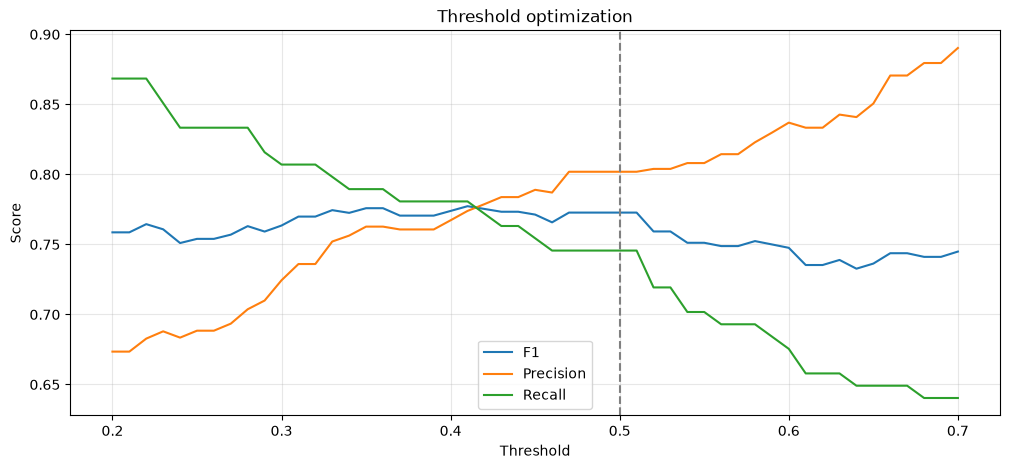

In [64]:
plt.figure(figsize=(12, 5))

plt.plot(threshold_results["threshold"],
         threshold_results["F1"], label="F1")

plt.plot(threshold_results["threshold"],
         threshold_results["Precision"], label="Precision")

plt.plot(threshold_results["threshold"],
         threshold_results["Recall"], label="Recall")

plt.axvline(0.5, linestyle="--", color="gray")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 8.2. Валидация оптимизированного порога

In [65]:
from sklearn.model_selection import StratifiedKFold

inner_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

nested_results = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Подбираем порог только на обучающих данных
    train_probs = cross_val_predict(
        build_model(),
        X_train,
        y_train,
        cv=inner_cv,
        method="predict_proba"
    )[:, 1]

    best_threshold = max(
        np.arange(0.20, 0.71, 0.01),
        key=lambda t: f1_score(
            y_train, (train_probs >= t).astype(int)
        )
    )

    # Обучаем модель и проверяем на внешнем фолде
    model = build_model()
    model.fit(X_train, y_train)

    test_probs = model.predict_proba(X_test)[:, 1]

    nested_results.append({
        "fold": fold,
        "threshold": best_threshold,
        "F1_original": f1_score(
            y_test, (test_probs >= 0.5).astype(int)
        ),
        "F1_optimized": f1_score(
            y_test, (test_probs >= best_threshold).astype(int)
        )
    })

nested_results = pd.DataFrame(nested_results)

display(nested_results.round(4))
display(nested_results.mean().round(4))

,fold,threshold,F1_original,F1_optimized
0,1,0.30,0.7500,0.7692
1,2,0.21,0.7391,0.6786
2,3,0.26,0.7692,0.7843
3,4,0.22,0.8261,0.7925
4,5,0.34,0.7805,0.7619


fold            3.0000
threshold       0.2660
F1_original     0.7730
F1_optimized    0.7573
dtype: float64

### 8.3. Исследование силы регуляризации

In [66]:
C_values = [
    0.001, 0.003,
    0.01, 0.03,
    0.1, 0.3,
    1.0, 3.0,
    10.0, 30.0, 100.0
]

regularization_results = []

for C in C_values:

    scores = cross_validate(
        build_model(C=C),
        X,
        y,
        cv=cv,
        scoring=["f1", "precision", "recall", "roc_auc"]
    )

    regularization_results.append({
        "C": C,
        "F1": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    })

regularization_results = pd.DataFrame(
    regularization_results
)

display(
    regularization_results
    .sort_values("F1", ascending=False)
    .round(4)
)

,C,F1,F1_std,Precision,Recall,ROC_AUC
6,1.000,0.7730,0.0302,0.8130,0.7455,0.9029
8,10.000,0.7621,0.0434,0.8033,0.7368,0.8956
7,3.000,0.7595,0.0427,0.8072,0.7277,0.9033
5,0.300,0.7484,0.0623,0.8023,0.7095,0.9005
9,30.000,0.7373,0.0458,0.7637,0.7194,0.8853
10,100.000,0.7373,0.0458,0.7637,0.7194,0.8758
3,0.030,0.7341,0.0714,0.8519,0.6569,0.8760
2,0.010,0.7284,0.0846,0.8929,0.6221,0.8689
4,0.100,0.7258,0.0657,0.7978,0.6747,0.8895
1,0.003,0.6878,0.1059,0.9236,0.5526,0.8559


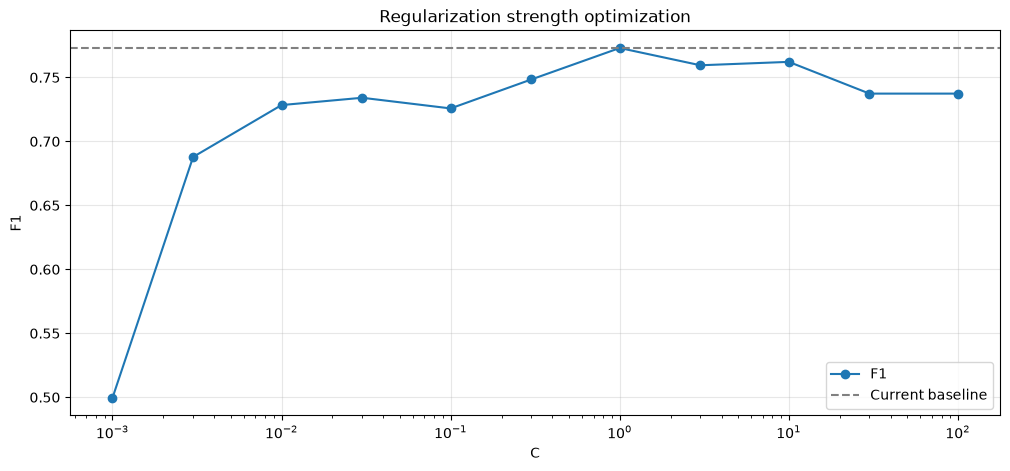

In [67]:
plt.figure(figsize=(12, 5))

plt.plot(
    regularization_results["C"],
    regularization_results["F1"],
    marker="o",
    label="F1"
)

plt.axhline(
    0.7730,
    color="gray",
    linestyle="--",
    label="Current baseline"
)

plt.xscale("log")
plt.xlabel("C")
plt.ylabel("F1")
plt.title("Regularization strength optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 8.4. Сравнение Logistic Regression и CatBoost

In [68]:
from catboost import CatBoostClassifier

# Подготовка данных
X_cat = X.copy()

X_cat[final_numeric] = X_cat[final_numeric].replace(
    [np.inf, -np.inf], np.nan
)

for col in categorical:
    X_cat[col] = (
        X_cat[col].astype("string")
        .fillna("unknown")
        .astype(str)
    )

# Создание модели
catboost_model = CatBoostClassifier(
    iterations=300,
    depth=4,
    learning_rate=0.03,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

# Кросс-валидация
catboost_scores = cross_validate(
    catboost_model,
    X_cat,
    y,
    cv=cv,
    scoring=["f1", "precision", "recall", "roc_auc"],
    params={"cat_features": categorical},
    error_score="raise"
)

# Расчёт метрик
catboost_results = {
    "F1": catboost_scores["test_f1"].mean(),
    "F1_std": catboost_scores["test_f1"].std(),
    "Precision": catboost_scores["test_precision"].mean(),
    "Recall": catboost_scores["test_recall"].mean(),
    "ROC_AUC": catboost_scores["test_roc_auc"].mean()
}

# Сравнение моделей
display(pd.DataFrame({
    "Logistic Regression": evaluate_features(
        final_numeric, categorical
    ),
    "CatBoost": catboost_results
}).T.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Logistic Regression,0.7730,0.0302,0.8130,0.7455,0.9029
CatBoost,0.7386,0.0650,0.8167,0.6830,0.8817


### 8.5. Проверка исторических признаков продавцов

In [69]:
seller_block_features = [
    "seller_previous_blocks",
    "seller_block_rate",
    "seller_has_block_history"
]

seller_activity_features = [
    "seller_previous_listings",
    "seller_previous_expired",
    "seller_previous_removed",
    "seller_expired_rate"
]

seller_experiments = {
    "Original": final_numeric,

    "Block history": (
        final_numeric + seller_block_features
    ),

    "Seller activity": (
        final_numeric + seller_activity_features
    ),

    "All seller features": (
        final_numeric
        + seller_block_features
        + seller_activity_features
    )
}

seller_results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in seller_experiments.items()
}).T

display(seller_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7730,0.0302,0.8130,0.7455,0.9029
Block history,0.7627,0.0376,0.8005,0.7368,0.9021
Seller activity,0.7510,0.0408,0.7963,0.7190,0.8999
All seller features,0.7443,0.0479,0.7947,0.7103,0.8962


In [70]:
print("Размеченных объявлений с историей продавца:")
print((research["seller_previous_listings"] > 0).sum())

print("\nРазмеченных объявлений с историей блокировок:")
print(research["seller_has_block_history"].sum())

Размеченных объявлений с историей продавца:
110

Размеченных объявлений с историей блокировок:
2


### 8.2. Сохранение CSV
Полная таблица содержит также экспериментальные признаки и служебные столбцы; отобранная таблица - только ID и признаки текущей модели. Разметка не сохраняется в таблицах признаков. Сохраняем также обработанные surveys, events и messages с исходными столбцами последних двух таблиц.

In [71]:
OUTPUT = Path("data_by_dewallen")
OUTPUT.mkdir(exist_ok=True)

features.to_csv(OUTPUT / "features.csv", index=False)
features[["listing_id"] + final_feature_columns].to_csv(
    OUTPUT / "best_features.csv", index=False
)
surveys.to_csv(OUTPUT / "surveys.csv", index=False)
events_clean[events.columns].to_csv(OUTPUT / "events.csv", index=False)
messages_clean[messages.columns].to_csv(OUTPUT / "messages.csv", index=False)

for path in sorted(OUTPUT.glob("*.csv")):
    print("Сохранено:", path)
print("Папка:", OUTPUT.resolve())

Сохранено: data_by_dewallen\best_features.csv
Сохранено: data_by_dewallen\events.csv
Сохранено: data_by_dewallen\features.csv
Сохранено: data_by_dewallen\messages.csv
Сохранено: data_by_dewallen\surveys.csv
Папка: C:\Users\sbitw\neuroslop_kygarikovs_hakaton\data_by_dewallen


### 8.3. Контроль экспортированных таблиц
Повторно читаем CSV и проверяем размеры и ключи. Для сравнения качества используем командный модуль `f1.py` (или его исходное имя `f1_check.py`, если файл ещё не переименован). Полная таблица включает также заголовки, даты и дублирующие столбцы; такой эксперимент не является чистым сравнением инженерных признаков. Если модуль отсутствует, основной ноутбук всё равно завершает работу.

In [72]:
full_df = pd.read_csv(OUTPUT / "features.csv")
best_df = pd.read_csv(OUTPUT / "best_features.csv")
assert full_df["listing_id"].is_unique and best_df["listing_id"].is_unique
assert full_df["listing_id"].equals(best_df["listing_id"])
assert len(best_df) == len(listings)
assert best_df.columns.tolist() == ["listing_id"] + final_feature_columns

full_df = full_df.merge(verified, on="listing_id", how="inner", validate="one_to_one")
best_df = best_df.merge(verified, on="listing_id", how="inner", validate="one_to_one")
print("All features (столбцы без ID и target):", full_df.drop(columns=["listing_id", "seller_id", "is_deal"], errors="ignore").shape[1])
print("Best features:", len(final_feature_columns))

from importlib.util import find_spec

if find_spec("f1") is not None:
    from f1 import evaluate_features as check_f1
elif find_spec("f1_check") is not None:
    from f1_check import evaluate_features as check_f1
else:
    check_f1 = None
    print("Командный модуль f1.py не найден. Сравнение CSV пропущено.")

if check_f1 is not None:
    export_results = pd.DataFrame({
        "All features": check_f1(full_df),
        "Best features": check_f1(best_df)
    }).T
    display(export_results.round(4))

All features (столбцы без ID и target): 120
Best features: 60


,F1,F1_std,Precision,Recall,ROC_AUC
All features,0.7467,0.0512,0.7608,0.7368,0.8784
Best features,0.7730,0.0302,0.8130,0.7455,0.9029


### 8.4. Следующие шаги
- Объединить отобранные признаки с NLP-признаками команды.
- Проверить другие модели и настройку порога с вложенной CV или независимым контролем.
- Оценить CatShareMAE и обработать все исключённые объявления перед финальным submission.